# Ringing a black hole in the time domain

From the course [*Black-hole perturbation theory*](https://svykho.github.io/lab/course/) by Alejandro Svyatkovskyy Kholyavka, [Lesson 12: Compute it yourself](https://svykho.github.io/lab/course/compute.html).

Throw a wave packet at a Schwarzschild black hole and record what comes back. This notebook solves the wave equation of Lessons 3 and 4,

$$-\frac{\partial^2\psi}{\partial t^2} + \frac{\partial^2\psi}{\partial r_*^2} - V(r)\,\psi = 0,$$

with the same finite-difference scheme that runs in the figures of the course. It then measures the quasinormal frequency from the signal ([Lesson 6](https://svykho.github.io/lab/course/quasinormal-modes.html)), checks that the numbers converge, and follows the signal long enough to see Price's tail ([Lesson 8](https://svykho.github.io/lab/course/tails.html)). It needs NumPy, SciPy and Matplotlib and runs in well under a minute.

Units: $G = c = M = 1$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import lambertw

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

## From the tortoise coordinate back to $r$

The grid is uniform in $r_* = r + 2\ln(r/2 - 1)$, but the potential is a function of $r$. The inverse has a closed form with the Lambert function $W$, the solution of $W e^W = x$:

$$r = 2\left[1 + W\!\left(e^{\,r_*/2 - 1}\right)\right].$$

It is exact from the horizon to $r_* \approx 1400$, where the exponential overflows.

In [2]:
def r_of_rstar(rs):
    return 2 * (1 + lambertw(np.exp(rs / 2 - 1)).real)


rs = np.array([-20.0, 0.0, 10.0, 100.0, 1000.0])
r = r_of_rstar(rs)
print("r* =", rs)
print("r  =", r)
print("check, r + 2 ln(r/2 - 1) =", r + 2 * np.log(r / 2 - 1))

r* = [ -20.    0.   10.  100. 1000.]
r  = [  2.0000334    2.55692909   7.85254212  92.37828628 987.59979359]
check, r + 2 ln(r/2 - 1) = [-2.0000000e+01  8.8817842e-16  1.0000000e+01  1.0000000e+02
  1.0000000e+03]


## The potentials

The four barriers of [Lesson 4](https://svykho.github.io/lab/course/gravitational-perturbations.html): Regge–Wheeler (axial gravitational), Zerilli (polar gravitational), scalar and electromagnetic.

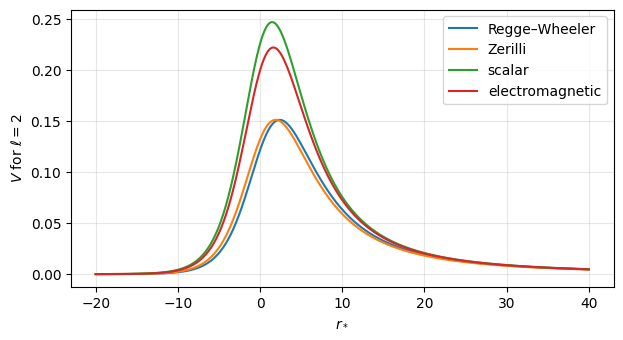

In [3]:
def V_rw(r, l):
    return (1 - 2 / r) * (l * (l + 1) / r**2 - 6 / r**3)


def V_scalar(r, l):
    return (1 - 2 / r) * (l * (l + 1) / r**2 + 2 / r**3)


def V_em(r, l):
    return (1 - 2 / r) * l * (l + 1) / r**2


def V_zerilli(r, l):
    lam = (l - 1) * (l + 2) / 2
    num = 2 * lam**2 * (lam + 1) * r**3 + 6 * lam**2 * r**2 + 18 * lam * r + 18
    return (1 - 2 / r) * num / (r**3 * (lam * r + 3) ** 2)


x = np.linspace(-20, 40, 600)
r = r_of_rstar(x)
fig, ax = plt.subplots(figsize=(7, 3.6))
for V, name in ((V_rw, "Regge–Wheeler"), (V_zerilli, "Zerilli"), (V_scalar, "scalar"), (V_em, "electromagnetic")):
    ax.plot(x, V(r, 2), label=name)
ax.set_xlabel(r"$r_*$")
ax.set_ylabel(r"$V$ for $\ell = 2$")
ax.legend()
plt.show()

## The scheme

On a grid with spacing $\Delta x$ in $r_*$ and $\Delta t$ in time, replace each second derivative by its centred difference. The value at the next time step is then given by the two previous ones (the "leapfrog" scheme):

$$\psi^{k+1}_j = 2\psi^k_j - \psi^{k-1}_j + \left(\frac{\Delta t}{\Delta x}\right)^2\left(\psi^k_{j+1} - 2\psi^k_j + \psi^k_{j-1}\right) - \Delta t^2\,V_j\,\psi^k_j .$$

Two details matter.

- **Stability.** Information must not travel more than one grid cell per step, so $\Delta t \le \Delta x$ (the Courant–Friedrichs–Lewy condition). We use $\Delta t = \Delta x/2$.
- **The ends of the grid.** Waves must leave the grid without bouncing back. At each end we impose that the wave only moves outwards, $\partial_t\psi = \pm\partial_{r_*}\psi$. This is exact where the potential vanishes; at the outer end the potential still falls off as $\ell(\ell+1)/r^2$, so a small reflection remains. We put that end far enough away that nothing reflected from it can reach the observer during the run.

The initial data are a packet moving towards the hole, $\psi(0, r_*) = g(r_*)$ and $\psi(-\Delta t, r_*) = g(r_* - \Delta t)$.

In [4]:
def evolve(V, g, x0, x1, dx, T, obs):
    """Leapfrog for -psi_tt + psi_xx - V psi = 0 on [x0, x1].
    V and g are functions of r*; g moves towards the hole.
    Returns the times and the signal at r* = obs."""
    dt = 0.5 * dx
    x = x0 + dx * np.arange(round((x1 - x0) / dx) + 1)
    Vdt2 = V(x) * dt**2
    old, now = g(x - dt), g(x)
    lam, c = (dt / dx) ** 2, dt / dx
    io = round((obs - x0) / dx)
    steps = round(T / dt)
    signal = np.empty(steps + 1)
    signal[0] = now[io]
    for k in range(1, steps + 1):
        new = np.empty_like(now)
        new[1:-1] = 2 * now[1:-1] - old[1:-1] + lam * (now[2:] - 2 * now[1:-1] + now[:-2]) - Vdt2[1:-1] * now[1:-1]
        new[0] = now[0] + c * (now[1] - now[0])  # outgoing towards the horizon
        new[-1] = now[-1] - c * (now[-1] - now[-2])  # outgoing towards infinity
        old, now = now, new
        signal[k] = now[io]
    return dt * np.arange(steps + 1), signal

## Hit it

The experiment of the figure in Lesson 6: a Gaussian packet of width $6M$, oscillating at $0.4/M$, starts at $r_* = 50M$ and travels inwards; the observer sits at $r_* = 100M$. The grid runs from $-300M$ to $600M$ with $\Delta x = 0.2M$.

4301 time steps; the signal peaks at t = 152.2M


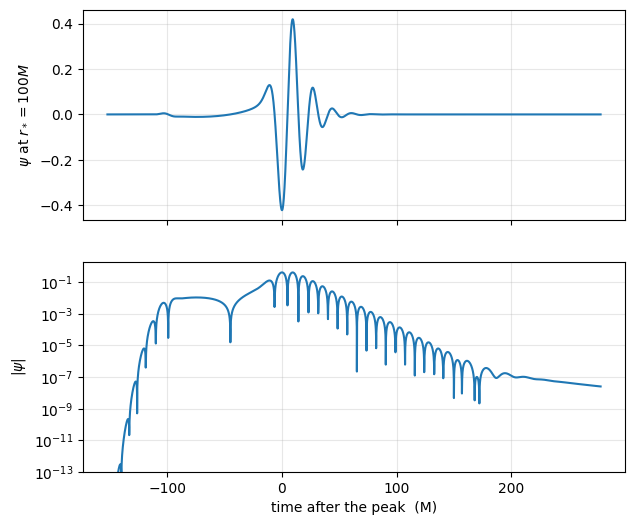

In [5]:
def packet(x, x0=50.0, sigma=6.0, nu=0.4):
    z = x - x0
    return np.exp(-z**2 / (2 * sigma**2)) * np.cos(nu * z)


l = 2
V = lambda x: V_rw(r_of_rstar(x), l)
t, psi = evolve(V, packet, -300, 600, 0.2, 430, obs=100)
ip = np.argmax(np.abs(psi))
print(f"{len(t)} time steps; the signal peaks at t = {t[ip]:.1f}M")

fig, (a1, a2) = plt.subplots(2, 1, figsize=(7, 6), sharex=True)
a1.plot(t - t[ip], psi)
a1.set_ylabel(r"$\psi$ at $r_* = 100M$")
a2.semilogy(t - t[ip], np.abs(psi))
a2.set_ylim(1e-13, 2)
a2.set_xlabel("time after the peak  (M)")
a2.set_ylabel(r"$|\psi|$")
plt.show()

On the logarithmic scale a damped sinusoid is a straight line, notched where it crosses zero. After about $200M$ the line bends: the ringing has decayed below the tail.

## Measure the frequency

Fit a single damped sinusoid to a window $40M$ long. A quick way that needs no initial guess is two-term linear prediction (Prony's method): a damped sinusoid sampled every $d$ obeys $y_{k} = c_1 y_{k-1} + c_2 y_{k-2}$ exactly. Find $c_1, c_2$ by least squares; the roots $z$ of $z^2 - c_1 z - c_2 = 0$ give $\omega = i\ln z/d$.

In [6]:
def prony(t, y, t0, t1, d=0.5):
    step = round(d / (t[1] - t[0]))
    yy = y[(t >= t0) & (t <= t1)][::step]
    A = np.column_stack([yy[1:-1], yy[:-2]])
    c1, c2 = np.linalg.lstsq(A, yy[2:], rcond=None)[0]
    z = np.roots([1, -c1, -c2]).astype(complex)
    w = 1j * np.log(z) / d
    return w[np.argmax(w.real)]


exact = 0.373672 - 0.088962j  # Leaver, Lesson 6
for u in (0, 10, 30, 60, 120):
    w = prony(t, psi, t[ip] + u, t[ip] + u + 40)
    print(f"fit from +{u:3d}M:  M omega = {w:.5f}   error {abs(w - exact) / abs(exact):.1e}")

fit from +  0M:  M omega = 0.34249-0.02944j   error 1.7e-01
fit from + 10M:  M omega = 0.35964-0.06773j   error 6.6e-02
fit from + 30M:  M omega = 0.37284-0.08836j   error 2.7e-03
fit from + 60M:  M omega = 0.37359-0.08923j   error 7.3e-04
fit from +120M:  M omega = 0.37210-0.08268j   error 1.7e-02


Scan the start of the window, as in the lower panel of the figure in Lesson 6. Too early, the overtones and the direct response spoil the fit; in the middle the signal is a single mode; too late, the tail takes over.

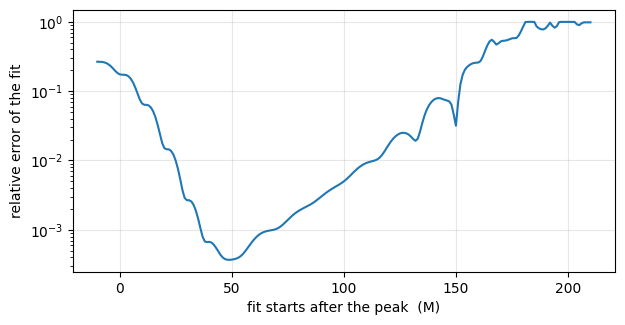

In [7]:
starts = np.arange(-10, 211, 1.0)
errs = [abs(prony(t, psi, t[ip] + u, t[ip] + u + 40) - exact) / abs(exact) for u in starts]
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.semilogy(starts, errs)
ax.set_xlabel("fit starts after the peak  (M)")
ax.set_ylabel("relative error of the fit")
plt.show()

## Is it right? A convergence test

A numerical answer means nothing until you know how far it is from the exact one. The scheme makes errors proportional to $\Delta x^2$, so halving the spacing should divide them by four. Without knowing the exact answer, compare three runs, with $\Delta x = h$, $h/2$ and $h/4$:

$$\frac{\psi_h - \psi_{h/2}}{\psi_{h/2} - \psi_{h/4}} \approx 2^p,$$

where $p$ is the order of the scheme. Here $p$ should be 2.

measured order of convergence: p = 2.02


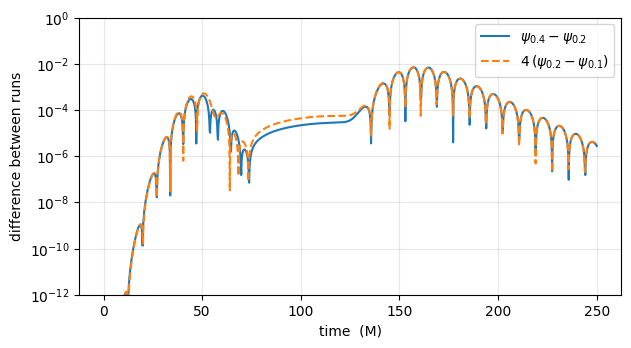

In [8]:
runs = {}
for dx in (0.4, 0.2, 0.1):
    tt, yy = evolve(V, packet, -150, 260, dx, 250, obs=100)
    every = round(0.2 / (tt[1] - tt[0]))  # compare on the common time grid, every 0.2M
    runs[dx] = (tt[::every], yy[::every])

tc = runs[0.4][0]
d1 = runs[0.4][1] - runs[0.2][1]
d2 = runs[0.2][1] - runs[0.1][1]
p = np.log2(np.linalg.norm(d1) / np.linalg.norm(d2))
print(f"measured order of convergence: p = {p:.2f}")

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.semilogy(tc, np.abs(d1), label=r"$\psi_{0.4} - \psi_{0.2}$")
ax.semilogy(tc, 4 * np.abs(d2), "--", label=r"$4\,(\psi_{0.2} - \psi_{0.1})$")
ax.set_ylim(1e-12, 1)
ax.set_xlabel("time  (M)")
ax.set_ylabel("difference between runs")
ax.legend()
plt.show()

The two curves lie on top of each other: the scheme is second order, and the difference between the two finest runs is a good estimate of the error of the finest one. The same test, live, is in the figure of Lesson 12.

The fitted frequency converges too. With the errors known to scale as $\Delta x^2$, two resolutions can be combined to cancel the leading error (Richardson extrapolation): $\omega_\infty \approx (4\,\omega_{h/2} - \omega_h)/3$.

In [9]:
tp = runs[0.1][0][np.argmax(np.abs(runs[0.1][1]))]  # the peak, from the finest run
fits = {dx: prony(tt, yy, tp + 50, tp + 90, d=0.4) for dx, (tt, yy) in runs.items()}
for dx, w in fits.items():
    print(f"dx = {dx}:  M omega = {w:.6f}")
r1, r2 = abs(fits[0.4] - fits[0.2]), abs(fits[0.2] - fits[0.1])
print(f"differences {r1:.1e} and {r2:.1e}, ratio {r1 / r2:.2f}")
rich = (4 * fits[0.1] - fits[0.2]) / 3
print(f"Richardson from 0.2 and 0.1:  M omega = {rich:.6f}")
print(f"difference with Leaver: {abs(rich - exact) / abs(exact):.1e}")

dx = 0.4:  M omega = 0.373889-0.088979j
dx = 0.2:  M omega = 0.373802-0.088903j
dx = 0.1:  M omega = 0.373780-0.088883j
differences 1.2e-04 and 2.9e-05, ratio 4.00
Richardson from 0.2 and 0.1:  M omega = 0.373772-0.088877j
difference with Leaver: 3.4e-04


Each halving of the grid divides the change by four, as it should for a second-order scheme. The grid error of the finest run is then about a third of the last difference, $10^{-5}$, and Richardson's value removes most of it. Yet the result still differs from Leaver's by about one part in three thousand, more than ten times the grid error. That is not a numerical error: the signal in the window is not a pure mode, because the overtones and the tail are still there, and a single damped sinusoid cannot describe them. A convergence test measures the error of the computer, not the error of the model.

## Axial and polar: the same notes

[Lesson 4](https://svykho.github.io/lab/course/gravitational-perturbations.html) says that the Regge–Wheeler and Zerilli barriers, which look different, ring at exactly the same frequencies. Check it.

In [10]:
for name, Vf in (("Regge–Wheeler", V_rw), ("Zerilli", V_zerilli)):
    tt, yy = evolve(lambda x: Vf(r_of_rstar(x), 2), packet, -300, 600, 0.2, 430, obs=100)
    i = np.argmax(np.abs(yy))
    print(f"{name:14s} M omega = {prony(tt, yy, tt[i] + 40, tt[i] + 80):.5f}")

Regge–Wheeler  M omega = 0.37342-0.08891j
Zerilli        M omega = 0.37342-0.08891j


## Price's tail

Follow a scalar field for $1500M$ ([Lesson 8](https://svykho.github.io/lab/course/tails.html)). Now the packet is a smooth bump, $\nu = 0$, starting at $r_* = 20M$, and the observer is at $r_* = 40M$. The grid is coarser, $\Delta x = 0.5M$, which is enough for the slow tail, and long enough that its ends cannot talk to the observer during the run.

On logarithmic axes a power law is a straight line. Its local slope, $p(t) = d\ln|\psi|/d\ln t$, should approach Price's value $-(2\ell + 3)$.

l = 0: local power at t = 800M is -3.10   (Price: -3)
l = 1: local power at t = 800M is -5.09   (Price: -5)
l = 2: local power at t = 800M is -7.08   (Price: -7)


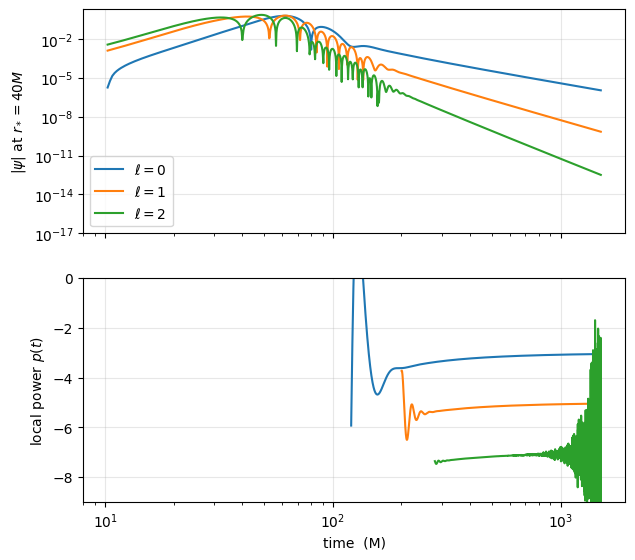

In [11]:
fig, (a1, a2) = plt.subplots(2, 1, figsize=(7, 6.4), sharex=True)
for l in (0, 1, 2):
    tt, yy = evolve(lambda x: V_scalar(r_of_rstar(x), l), lambda x: packet(x, 20.0, 6.0, 0.0),
                    -800, 850, 0.5, 1500, obs=40)
    m = tt > 10
    a1.loglog(tt[m], np.abs(yy[m]), label=f"$\\ell = {l}$")
    slope = np.gradient(np.log(np.abs(yy[m])), np.log(tt[m]))
    late = tt[m] > 120 + 80 * l  # after the ringing, which lasts longer for higher l
    a2.semilogx(tt[m][late], slope[late])
    k = np.searchsorted(tt[m][late], 800)
    print(f"l = {l}: local power at t = 800M is {slope[late][k]:.2f}   (Price: {-(2 * l + 3)})")
a1.set_ylim(1e-17, 2)
a1.set_ylabel(r"$|\psi|$ at $r_* = 40M$")
a1.legend()
a2.set_ylim(-9, 0)
a2.set_xlabel("time  (M)")
a2.set_ylabel("local power $p(t)$")
plt.show()

The power heads to $-3$, $-5$ and $-7$, slowly. For $\ell = 2$ the tail is close to the rounding errors of the computer, about $10^{-15}$ relative to the peak, and after about $1000M$ the slope becomes noisy.

## Try this

- Change the packet's oscillation to $\nu = 0.4$ in the tail experiment. The ringing hardly changes; the tail drops by the factor the packet's spectrum at zero frequency predicts ([Lesson 8](https://svykho.github.io/lab/course/tails.html)).
- Set $\Delta t = 1.01\,\Delta x$ and watch the scheme blow up.
- Move the outer end of the grid in to $r_* = 250M$ in the first experiment and look for the reflection in the logarithmic plot.